# COM7022 Machine Learning – Task 1
## Part 2: Feature Selection, Clustering and Evaluation
**Input:** `sales_clean.csv` (output of Part 1)

**Goal:** group products by their characteristics and sales performance, compare three clustering methods
(K-Means, Hierarchical, DBSCAN), choose the most suitable one, and describe the resulting product segments.

In [ ]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

### 2.1 Load the cleaned data

In [ ]:
# Finds the cleaned file even if Colab renamed it on upload (e.g. 'sales_clean (1).csv')
path = sorted(glob.glob('sales_clean*.csv'))[0]
df = pd.read_csv(path)
print('Loaded', path, df.shape)
df.head()

Loaded sales_clean (1).csv (994, 20)


,brand,details,category,price,price_text,available,stock_text,sold,last_updated,location,per_unit_listing,stock_status,category_group,country,is_us_seller,is_named_brand,days_since_update,log_sold,log_price,revenue_est
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,116.0,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States",1,More than 10,Eau de Parfum / Parfum,United States,1,1,0.0,4.762174,4.454231,9858.84
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,109.99,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada",0,2-10,Eau de Parfum / Parfum,Canada,0,0,0.0,3.891820,4.709440,5279.52
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States",0,More than 10,Eau de Toilette,United States,1,0,1.0,3.332205,4.615121,2700.00
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,44.99,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States",1,2-10,Eau de Toilette,United States,1,1,0.0,5.075174,3.828424,7153.41
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,5.0,Limited quantity available / 156 sold,156.0,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States",0,Limited,Fragrance (unspecified),United States,1,1,0.0,5.056246,2.885359,2637.96


### 2.2 Feature selection
The business question is *which products behave alike in terms of price, sales performance and stock*.
Each candidate column was assessed against that question:

| Feature | Decision | Reason |
|---|---|---|
| `price` → `log_price` | **Include** | Core product characteristic; log reduces right skew |
| `sold` → `log_sold` | **Include** | Core sales-performance measure; raw values extremely skewed (skew ≈ 9.8) |
| `available` → `log_available` | **Include** | Stock level; capped at 10 because the platform reports anything above 10 as "More than 10" |
| `category_group` | Tested, then used for **profiling** only | One-hot dummies dominate the distances (see 2.4) |
| `is_named_brand` | Profiling only | 93% of rows are 1, so it adds almost no variation and creates an artificial split |
| `is_us_seller` | Profiling only | 91% are US sellers; near-constant |
| `days_since_update` | Exclude | Describes seller activity rather than the product; 5% missing |
| `revenue_est` | Exclude | It is price × sold, so it would double-count existing features |
| `details`, `brand`, `location` (text) | Exclude | Free text / high cardinality (246 brands, 276 cities) |

In [ ]:
# Cap available at 10 to match the platform's reporting limit, then log-transform
df['available_capped'] = df['available'].clip(upper=10)
df['log_available'] = np.log1p(df['available_capped'])

FEATURES = ['log_price', 'log_sold', 'log_available']
X = df[FEATURES]
X.describe().round(2)

,log_price,log_sold,log_available
count,994.00,994.00,994.00
mean,3.63,4.29,1.98
std,0.67,2.07,0.51
min,1.39,0.69,0.69
25%,3.18,2.71,1.61
50%,3.60,3.92,2.20
75%,4.09,5.77,2.40
max,5.56,10.90,2.40


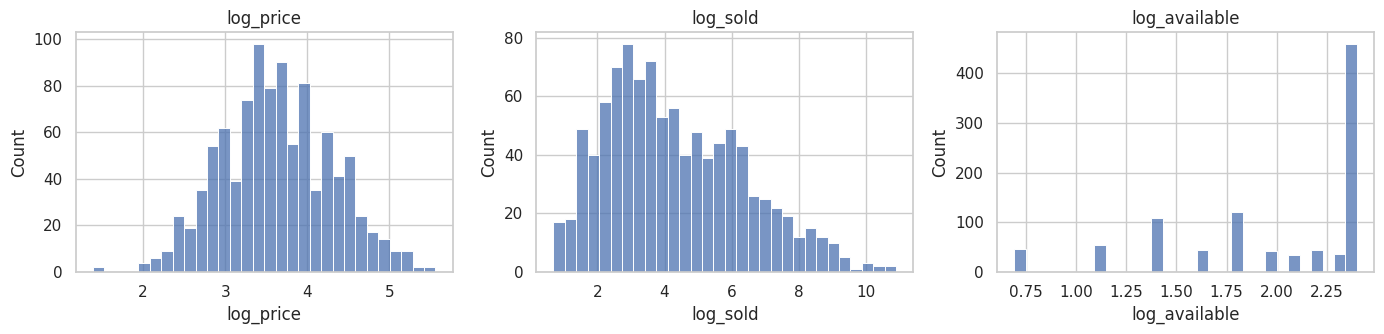

Correlation between selected features:


,log_price,log_sold,log_available
log_price,1.00,-0.15,-0.16
log_sold,-0.15,1.00,0.28
log_available,-0.16,0.28,1.00


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, FEATURES):
    sns.histplot(X[col], bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print('Correlation between selected features:')
X.corr().round(2)

### 2.3 Scaling
K-Means, Ward hierarchical clustering and DBSCAN all measure **Euclidean distance**, so features on larger scales would dominate.
`StandardScaler` puts each feature on mean 0 and standard deviation 1. The log transforms applied earlier already limit the effect of extreme values,
so a standard scaler (rather than a robust scaler) is sufficient.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=FEATURES).describe().round(2)

,log_price,log_sold,log_available
count,994.00,994.00,994.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-3.35,-1.74,-2.54
25%,-0.67,-0.77,-0.73
50%,-0.04,-0.18,0.42
75%,0.70,0.72,0.82
max,2.89,3.20,0.82


### 2.4 Treatment of the categorical variable: an experiment
To decide how to handle `category_group`, K-Means is run with and without one-hot encoded categories.

In [ ]:
cat_dummies = pd.get_dummies(df['category_group'], prefix='cat').astype(int)
X_with_cat = StandardScaler().fit_transform(pd.concat([X, cat_dummies], axis=1))

rows = []
for k in range(2, 9):
    lab_a = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_scaled)
    lab_b = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_with_cat)
    rows.append({'k': k,
                 'silhouette_numeric_only': silhouette_score(X_scaled, lab_a),
                 'silhouette_with_categories': silhouette_score(X_with_cat, lab_b)})
pd.DataFrame(rows).round(3)

,k,silhouette_numeric_only,silhouette_with_categories
0,2,0.320,0.289
1,3,0.292,0.361
2,4,0.300,0.406
3,5,0.296,0.439
4,6,0.283,0.452
5,7,0.291,0.376
6,8,0.288,0.359


In [ ]:
# What do the clusters look like when categories are included?
lab_cat = KMeans(n_clusters=6, n_init=20, random_state=RANDOM_STATE).fit_predict(X_with_cat)
pd.crosstab(lab_cat, df['category_group'])

category_group,Eau de Cologne,Eau de Parfum / Parfum,Eau de Toilette,Fragrance (unspecified),Gift set / Sampler,Other
row_0,,,,,,
0,0,390,0,0,0,0
1,0,0,462,0,0,0
2,0,0,0,0,6,0
3,69,0,0,0,0,0
4,0,0,0,35,0,0
5,0,0,0,0,0,32


**Finding:** with categories included, the silhouette score rises steadily with k, which looks better on paper.
However, the cross-tab shows why: the algorithm simply puts each category into its own cluster.
The binary dummy columns create large, artificial gaps that outweigh price and sales behaviour, so the "clusters" only repeat a label we already have.

**Decision:** cluster on the three numeric performance features, and use category, brand and location afterwards to **describe** each cluster.
This is a deliberate trade-off: a slightly lower silhouette score in exchange for segments that actually reveal something new.

### 2.5 Dimensionality reduction with PCA
PCA is used to check how much structure the three features share and to create 2-D plots of the clusters.

In [ ]:
pca = PCA(random_state=RANDOM_STATE)
pca.fit(X_scaled)

explained = pd.DataFrame({'component': [f'PC{i+1}' for i in range(len(FEATURES))],
                          'explained_variance_%': (pca.explained_variance_ratio_ * 100).round(1),
                          'cumulative_%': (np.cumsum(pca.explained_variance_ratio_) * 100).round(1)})
display(explained)

loadings = pd.DataFrame(pca.components_.T, index=FEATURES,
                        columns=[f'PC{i+1}' for i in range(len(FEATURES))]).round(2)
loadings

,component,explained_variance_%,cumulative_%
0,PC1,46.7,46.7
1,PC2,29.3,76.0
2,PC3,24.0,100.0


,PC1,PC2,PC3
log_price,-0.48,0.88,0.05
log_sold,0.62,0.38,-0.69
log_available,0.62,0.30,0.72


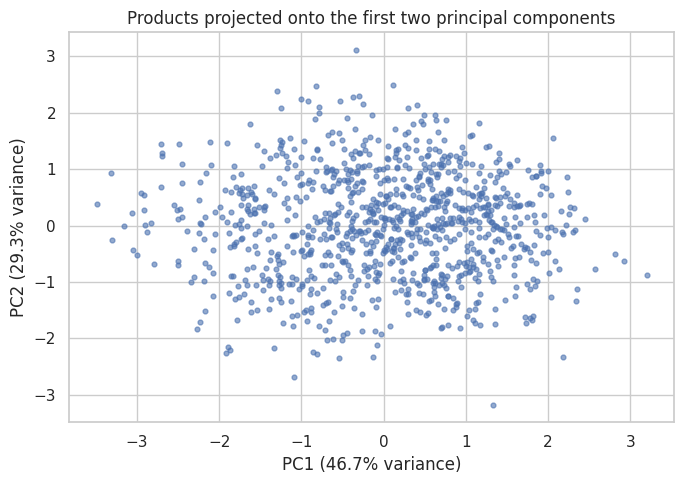

In [ ]:
X_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=12, alpha=0.6)
plt.xlabel(f'PC1 ({explained.iloc[0, 1]}% variance)')
plt.ylabel(f'PC2 ({explained.iloc[1, 1]}% variance)')
plt.title('Products projected onto the first two principal components')
plt.tight_layout()
plt.show()

With only three input features, PCA is used for **visualisation**, not for reducing the model input.
The first two components keep most of the variance (see table), so the 2-D plots are a fair picture of the clusters.
No obvious, well-separated groups are visible. This suggests the products form a continuous spread rather than clean natural clusters,
which matters for interpreting the evaluation scores later.

### 2.6 Model 1: K-Means
**Choosing k:** the elbow method (inertia) and the silhouette score are calculated for k = 2 to 10.

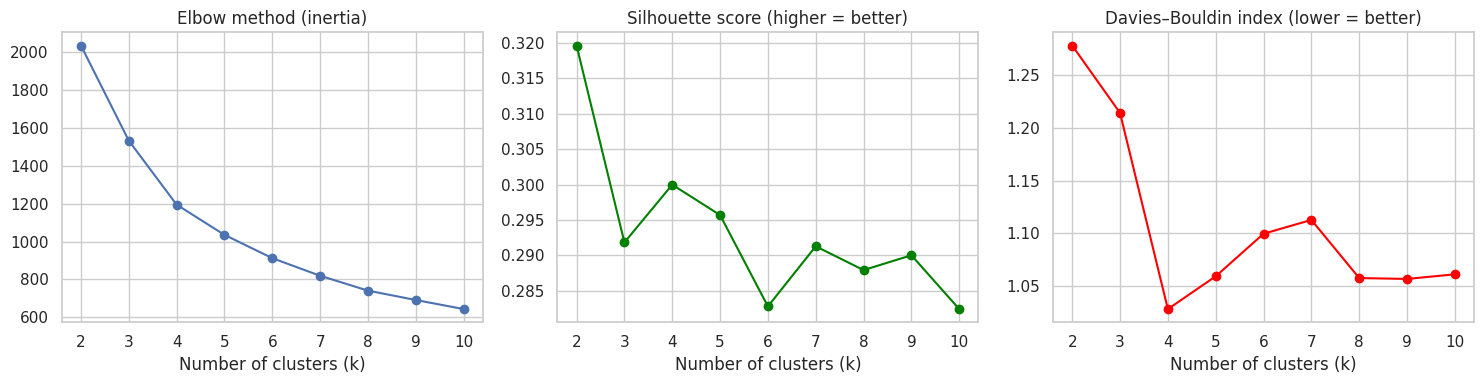

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,2034.916,0.320,1.278,461.693
1,3,1532.643,0.292,1.214,468.577
2,4,1194.848,0.300,1.028,493.586
3,5,1035.397,0.296,1.059,464.844
4,6,912.321,0.283,1.099,448.273
5,7,819.443,0.291,1.113,434.149
6,8,740.907,0.288,1.057,426.065
7,9,691.466,0.290,1.057,407.861
8,10,643.570,0.282,1.061,397.266


In [ ]:
k_range = range(2, 11)
km_results = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    km_results.append({'k': k,
                       'inertia': km.inertia_,
                       'silhouette': silhouette_score(X_scaled, labels),
                       'davies_bouldin': davies_bouldin_score(X_scaled, labels),
                       'calinski_harabasz': calinski_harabasz_score(X_scaled, labels)})
km_results = pd.DataFrame(km_results)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(km_results['k'], km_results['inertia'], 'o-')
axes[0].set_title('Elbow method (inertia)')
axes[1].plot(km_results['k'], km_results['silhouette'], 'o-', color='green')
axes[1].set_title('Silhouette score (higher = better)')
axes[2].plot(km_results['k'], km_results['davies_bouldin'], 'o-', color='red')
axes[2].set_title('Davies–Bouldin index (lower = better)')
for ax in axes:
    ax.set_xlabel('Number of clusters (k)')
plt.tight_layout()
plt.show()

km_results.round(3)

**Choice of k = 4:** the elbow bends around k = 3–4, the silhouette score stays in a narrow band for all k,
the Davies–Bouldin index reaches its lowest value at k = 4, and the Calinski–Harabasz score is highest at k = 4.
Three of the four measures therefore point to the same answer. Four segments are also a practical number for the business to act on.

In [ ]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE)
df['kmeans'] = kmeans.fit_predict(X_scaled)
df['kmeans'].value_counts().sort_index()

,count
kmeans,
0,259
1,233
2,267
3,235


In [ ]:
# Stability check: do different random starts give the same clusters?
# Adjusted Rand Index (ARI) = 1 means identical groupings
stability = [adjusted_rand_score(df['kmeans'],
                                 KMeans(n_clusters=K, n_init=20, random_state=s).fit_predict(X_scaled))
             for s in range(10)]
print('ARI across 10 random seeds: mean = %.3f, min = %.3f' % (np.mean(stability), np.min(stability)))

ARI across 10 random seeds: mean = 0.996, min = 0.978


### 2.7 Model 2: Hierarchical (Agglomerative) Clustering
Ward linkage is used because, like K-Means, it minimises within-cluster variance, which makes the two methods directly comparable.
The dendrogram shows how products merge into groups.

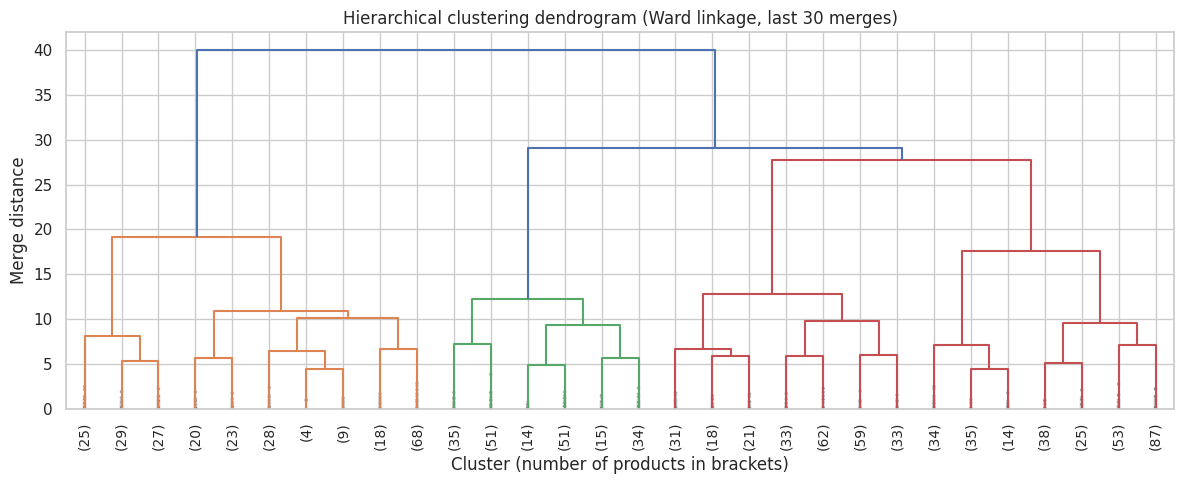

In [ ]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, show_contracted=True)
plt.title('Hierarchical clustering dendrogram (Ward linkage, last 30 merges)')
plt.xlabel('Cluster (number of products in brackets)')
plt.ylabel('Merge distance')
plt.tight_layout()
plt.show()

In [ ]:
hc_results = []
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    hc_results.append({'k': k,
                       'silhouette': silhouette_score(X_scaled, labels),
                       'davies_bouldin': davies_bouldin_score(X_scaled, labels)})
pd.DataFrame(hc_results).round(3)

,k,silhouette,davies_bouldin
0,2,0.302,1.301
1,3,0.228,1.282
2,4,0.250,1.166
3,5,0.249,1.122
4,6,0.234,1.084
5,7,0.237,1.135
6,8,0.233,1.198


In [ ]:
hierarchical = AgglomerativeClustering(n_clusters=K, linkage='ward')
df['hierarchical'] = hierarchical.fit_predict(X_scaled)
print(df['hierarchical'].value_counts().sort_index())
print('Agreement with K-Means (ARI): %.3f' % adjusted_rand_score(df['kmeans'], df['hierarchical']))

hierarchical
0    251
1    286
2    200
3    257
Name: count, dtype: int64
Agreement with K-Means (ARI): 0.554


### 2.8 Model 3: DBSCAN
DBSCAN finds dense regions and labels isolated points as **noise** (-1), so it does not need k in advance.
It needs two settings:
- `min_samples`: a common rule of thumb is about 2 × number of features; 8 is used here.
- `eps`: chosen from the **k-distance plot**, where the curve bends upwards sharply.

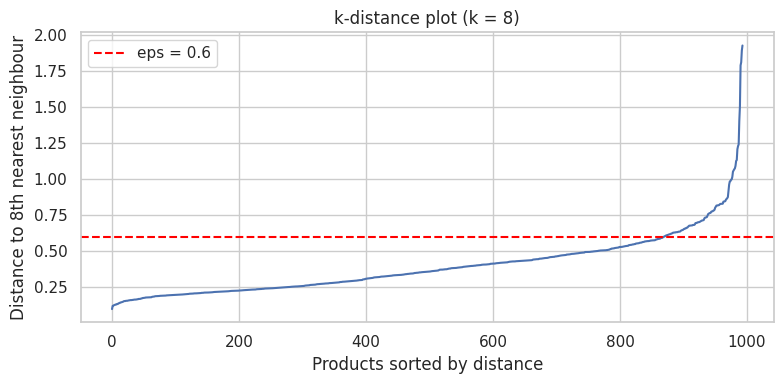

In [ ]:
MIN_SAMPLES = 8
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled)
distances = np.sort(nn.kneighbors(X_scaled)[0][:, -1])

plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.axhline(0.6, color='red', linestyle='--', label='eps = 0.6')
plt.title(f'k-distance plot (k = {MIN_SAMPLES})')
plt.xlabel('Products sorted by distance')
plt.ylabel(f'Distance to {MIN_SAMPLES}th nearest neighbour')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Sensitivity check: how do results change with eps and min_samples?
grid = []
for ms in [5, 8, 10]:
    for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        mask = labels != -1
        sil = silhouette_score(X_scaled[mask], labels[mask]) if n_clusters > 1 else np.nan
        grid.append({'min_samples': ms, 'eps': eps, 'clusters': n_clusters,
                     'noise_%': round((labels == -1).mean() * 100, 1),
                     'silhouette_excl_noise': sil})
pd.DataFrame(grid).round(3)

,min_samples,eps,clusters,noise_%,silhouette_excl_noise
0,5,0.3,17,30.8,-0.089
1,5,0.4,13,12.8,-0.122
2,5,0.5,4,6.1,0.041
3,5,0.6,2,2.5,0.333
4,5,0.7,2,1.3,0.330
5,5,0.8,1,0.9,NaN
6,8,0.3,7,48.5,0.067
7,8,0.4,6,26.1,0.104
8,8,0.5,5,11.1,0.069
9,8,0.6,3,4.9,0.279


In [ ]:
dbscan = DBSCAN(eps=0.6, min_samples=MIN_SAMPLES)
df['dbscan'] = dbscan.fit_predict(X_scaled)
print(df['dbscan'].value_counts().sort_index())

dbscan
-1     49
 0    913
 1     15
 2     17
Name: count, dtype: int64


DBSCAN is very sensitive to `eps`: small values break the data into many tiny groups with a lot of noise,
while larger values merge almost everything into one cluster. This confirms what the PCA plot suggested:
the products form one large, continuous cloud of similar density, which is not the shape DBSCAN is designed for.
Its useful contribution here is identifying **unusual products** (the noise points).

In [ ]:
noise = df[df['dbscan'] == -1]
print(f'{len(noise)} products flagged as noise / outliers by DBSCAN')
noise[['details', 'price', 'sold', 'available', 'category_group']].sort_values('sold', ascending=False).head(10)

49 products flagged as noise / outliers by DBSCAN


,details,price,sold,available,category_group
81,Ck One by Calvin Klein Cologne Perfume Unisex ...,23.89,54052.0,5.0,Other
61,6 For $19.95 MEN(M) WOMEN(W) & UNISEX(U) Body ...,6.65,18882.0,9.0,Other
223,mini cologne Versace Pour Homme for Men Brand ...,8.84,9410.0,10.0,Eau de Toilette
376,YACHT MAN RED by Myrurgia 3.3 / 3.4 oz EDT Col...,9.98,8453.0,36.0,Eau de Toilette
755,GUCCI GUILTY POUR HOMME * Cologne for Men * ED...,58.46,5227.0,1.0,Eau de Toilette
310,Bentley Intense by Bentley 3.4 oz EDP Cologne ...,29.12,5145.0,1.0,Eau de Parfum / Parfum
840,Men's Cologne Sample Spray Vials - Choose Scen...,3.50,3009.0,4.0,Eau de Toilette
774,Lacoste Eau De Lacoste Blanc L.12.12 Cologne f...,54.50,1995.0,2.0,Eau de Toilette
404,X1 Bath & Body Works Men's Collection Cologne ...,27.94,717.0,1.0,Eau de Cologne
930,Diesel Only The Brave by Diesel EDT Cologne fo...,56.00,677.0,3.0,Eau de Toilette


### 2.9 Model comparison

In [ ]:
def evaluate(labels, name, exclude_noise=False):
    labels = np.asarray(labels)
    mask = labels != -1 if exclude_noise else np.ones(len(labels), dtype=bool)
    Xm, lm = X_scaled[mask], labels[mask]
    return {'model': name,
            'clusters': len(set(lm)),
            'noise_%': round((labels == -1).mean() * 100, 1),
            'silhouette': silhouette_score(Xm, lm),
            'davies_bouldin': davies_bouldin_score(Xm, lm),
            'calinski_harabasz': calinski_harabasz_score(Xm, lm)}

comparison = pd.DataFrame([
    evaluate(df['kmeans'], 'K-Means (k=4)'),
    evaluate(df['hierarchical'], 'Hierarchical Ward (k=4)'),
    evaluate(df['dbscan'], 'DBSCAN (eps=0.6, min_samples=8)', exclude_noise=True),
]).round(3)
comparison

,model,clusters,noise_%,silhouette,davies_bouldin,calinski_harabasz
0,K-Means (k=4),4,0.0,0.300,1.028,493.586
1,Hierarchical Ward (k=4),4,0.0,0.250,1.166,386.525
2,"DBSCAN (eps=0.6, min_samples=8)",3,4.9,0.279,0.685,58.458


*Silhouette: higher is better (range -1 to 1). Davies–Bouldin: lower is better. Calinski–Harabasz: higher is better.
DBSCAN's scores are calculated without its noise points, which flatters it. Its low Davies–Bouldin value is also misleading:
check the cluster sizes in 2.8, where one cluster holds over 90% of all products. In practice it separates "normal products" from a few small groups and outliers,
which is not a useful segmentation for the business.*

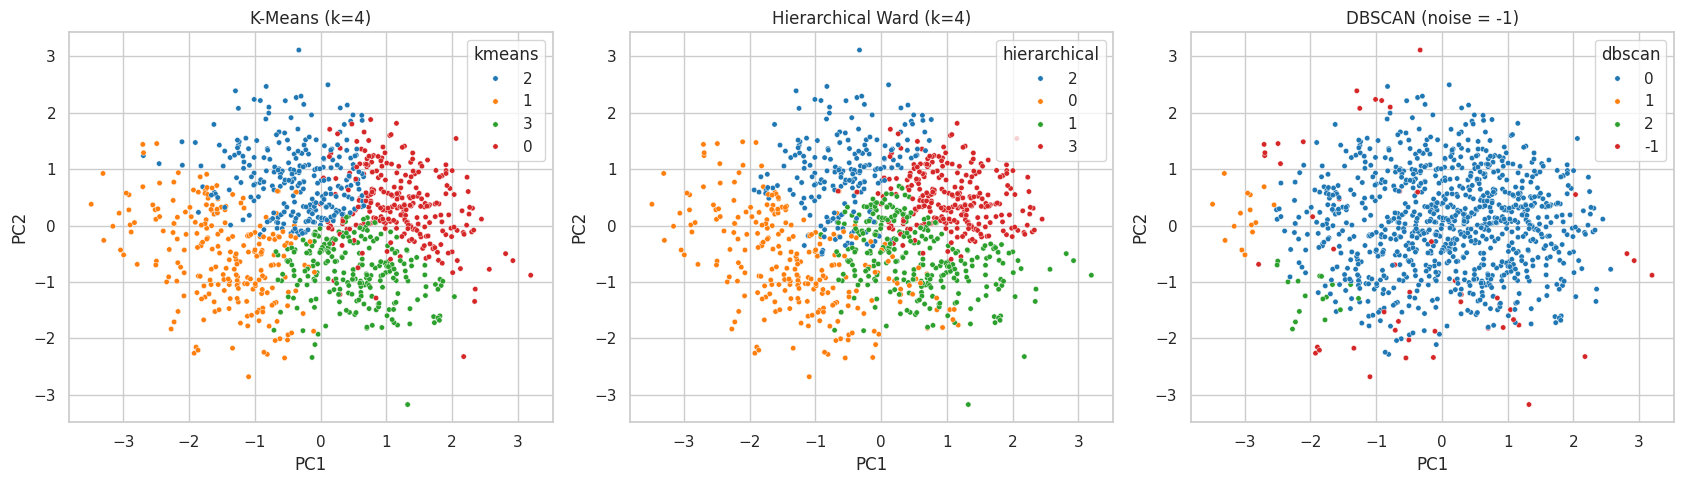

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, title in zip(axes,
                          ['kmeans', 'hierarchical', 'dbscan'],
                          ['K-Means (k=4)', 'Hierarchical Ward (k=4)', 'DBSCAN (noise = -1)']):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df[col].astype(str),
                    palette='tab10', s=15, ax=ax, legend='brief')
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

### 2.10 Final model: K-Means (k = 4)
K-Means is selected because it has the best balance of evaluation scores, is fully stable across random starts,
produces balanced segments, and is the simplest to explain and to re-run on new products (new items can be assigned to the nearest centre).

**Cluster profiles in original units (medians):**

In [ ]:
profile = df.groupby('kmeans').agg(
    products=('price', 'size'),
    median_price=('price', 'median'),
    median_sold=('sold', 'median'),
    median_available=('available_capped', 'median'),
    total_units_sold=('sold', 'sum'),
    est_revenue=('revenue_est', 'sum'),
    named_brand_pct=('is_named_brand', 'mean'),
    us_seller_pct=('is_us_seller', 'mean'))

profile['share_of_products_%'] = (profile['products'] / profile['products'].sum() * 100).round(1)
profile['share_of_revenue_%'] = (profile['est_revenue'] / profile['est_revenue'].sum() * 100).round(1)
profile['named_brand_pct'] = (profile['named_brand_pct'] * 100).round(1)
profile['us_seller_pct'] = (profile['us_seller_pct'] * 100).round(1)
profile.round(1)

,products,median_price,median_sold,median_available,total_units_sold,est_revenue,named_brand_pct,us_seller_pct,share_of_products_%,share_of_revenue_%
kmeans,,,,,,,,,,
0,259,30.0,803.0,10.0,701203.0,22410097.6,98.1,99.2,26.1,86.8
1,233,40.0,14.0,3.0,22196.0,1001681.9,95.7,90.1,23.4,3.9
2,267,68.6,35.0,10.0,24095.0,2152921.2,91.4,81.6,26.9,8.3
3,235,19.0,31.0,10.0,14175.0,244507.4,87.2,94.0,23.6,0.9


In [ ]:
# Give each cluster a business-friendly name based on its profile.
# (Cluster numbers can differ between computers, so names are assigned by rules, not by number.)
names = {}
remaining = list(profile.index)

best = profile.loc[remaining, 'median_sold'].idxmax()
names[best] = 'Bestsellers'
remaining.remove(best)

low_stock = profile.loc[remaining, 'median_available'].idxmin()
names[low_stock] = 'Low-stock slow movers'
remaining.remove(low_stock)

premium = profile.loc[remaining, 'median_price'].idxmax()
names[premium] = 'Premium niche'
remaining.remove(premium)

names[remaining[0]] = 'Budget range'

df['segment'] = df['kmeans'].map(names)
profile.index = profile.index.map(names)
profile[['products', 'share_of_products_%', 'median_price', 'median_sold',
         'median_available', 'share_of_revenue_%']].round(1)

,products,share_of_products_%,median_price,median_sold,median_available,share_of_revenue_%
kmeans,,,,,,
Bestsellers,259,26.1,30.0,803.0,10.0,86.8
Low-stock slow movers,233,23.4,40.0,14.0,3.0,3.9
Premium niche,267,26.9,68.6,35.0,10.0,8.3
Budget range,235,23.6,19.0,31.0,10.0,0.9


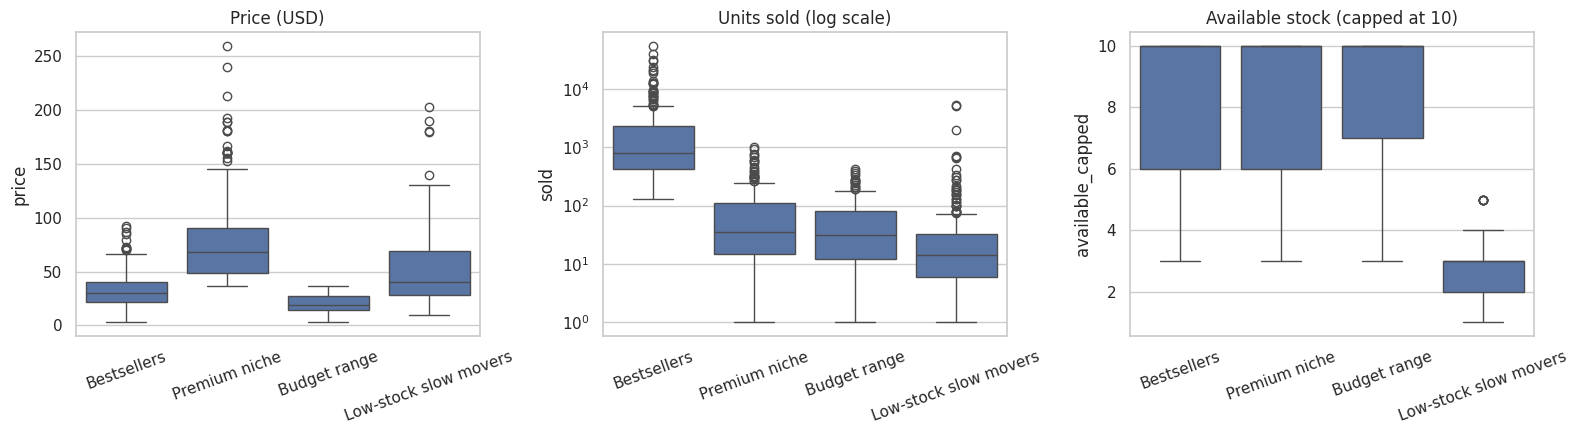

In [ ]:
order = ['Bestsellers', 'Premium niche', 'Budget range', 'Low-stock slow movers']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x='segment', y='price', order=order, ax=axes[0])
axes[0].set_title('Price (USD)')
sns.boxplot(data=df, x='segment', y='sold', order=order, ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Units sold (log scale)')
sns.boxplot(data=df, x='segment', y='available_capped', order=order, ax=axes[2])
axes[2].set_title('Available stock (capped at 10)')
for ax in axes:
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

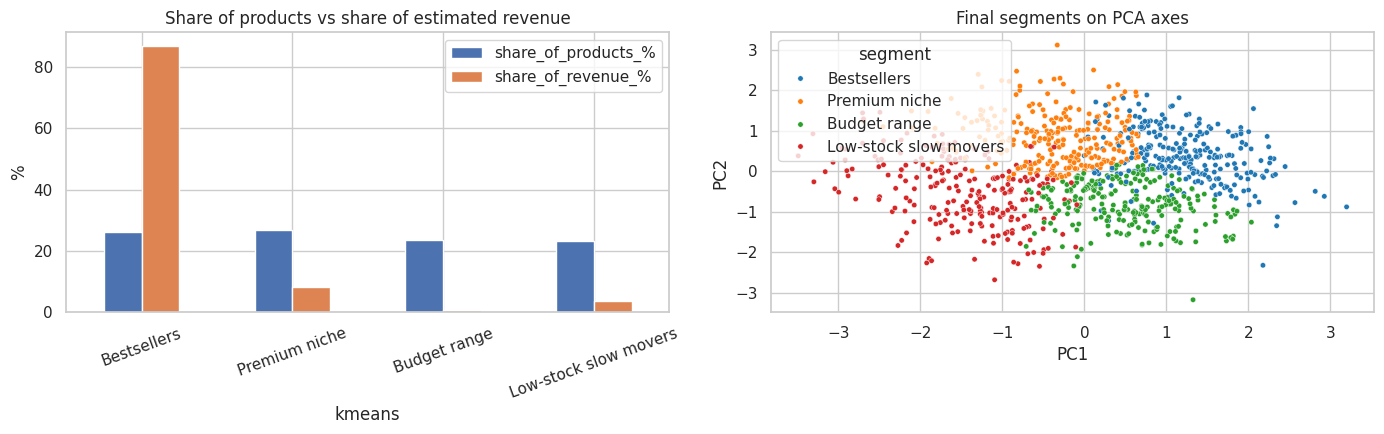

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
profile.loc[order, ['share_of_products_%', 'share_of_revenue_%']].plot(kind='bar', ax=axes[0])
axes[0].set_title('Share of products vs share of estimated revenue')
axes[0].set_ylabel('%')
axes[0].tick_params(axis='x', rotation=20)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['segment'], hue_order=order,
                palette='tab10', s=15, ax=axes[1])
axes[1].set_title('Final segments on PCA axes')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
plt.tight_layout()
plt.show()

**How the descriptive variables are spread across the segments:**

In [ ]:
pd.crosstab(df['segment'], df['stock_status'], normalize='index').loc[order].mul(100).round(1)

stock_status,2-10,Last one,Limited,More than 10
segment,,,,
Bestsellers,20.5,0.0,16.6,62.9
Premium niche,51.7,0.0,4.5,43.8
Budget range,40.4,0.0,1.7,57.9
Low-stock slow movers,79.8,20.2,0.0,0.0


In [ ]:
pd.crosstab(df['segment'], df['category_group'], normalize='index').loc[order].mul(100).round(1)

category_group,Eau de Cologne,Eau de Parfum / Parfum,Eau de Toilette,Fragrance (unspecified),Gift set / Sampler,Other
segment,,,,,,
Bestsellers,7.7,21.6,68.7,0.0,0.4,1.5
Premium niche,3.7,53.9,39.7,0.4,0.7,1.5
Budget range,7.2,42.1,40.0,2.6,0.9,7.2
Low-stock slow movers,9.4,39.1,36.1,12.0,0.4,3.0


In [ ]:
# Example products from each segment
for seg in order:
    print(f'\n=== {seg} ===')
    sample = df[df['segment'] == seg].sort_values('sold', ascending=False).head(5)
    print(sample[['details', 'price', 'sold', 'available']].to_string(index=False))


=== Bestsellers ===
                                                         details  price    sold  available
 Ck One by Calvin Klein Cologne Perfume Unisex 3.4 oz New In Box  23.89 54052.0        5.0
    Cool Water by Davidoff 4.2 oz EDT Cologne for Men New In Box  25.23 40130.0        5.0
Versace Eros by Gianni Versace 3.4 oz EDT Cologne for Men Tester  39.77 31718.0        5.0
    Chrome by Azzaro 6.7 / 6.8 oz EDT Cologne for Men New In Box  46.33 30655.0        5.0
   OBSESSION by Calvin Klein 4.0 oz 4 MEN edt Cologne New in Box  23.56 24048.0        5.0

=== Premium niche ===
                                                                         details  price   sold  available
Jean Paul Gaultier Le Male LE PARFUM 4.2 oz. Eau de Parfum INTENSE Spray. NO BOX  94.99 1024.0       10.0
  Azzaro The Most Wanted 3.3 oz./100 ml. PARFUM Spray for Men. New in Sealed Box  89.97  920.0       10.0
              Prada L'Homme Intense 3.3 oz./ 100 ml. Eau De Parfum Spray for Men 113.98  755

In [ ]:
df.to_csv('sales_clustered.csv', index=False)
print('Saved sales_clustered.csv')

Saved sales_clustered.csv
